In [ ]:
import os
import pickle
import random
import shutil
from copy import deepcopy
from datetime import timedelta
from pathlib import Path
from time import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import patches
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from ultralytics import YOLO

sns.set_theme()

data_path = Path("./data")
models_path = Path("./models")
yolo_results_path = Path("./runs/detect")

bccd_path = data_path / "BCCD"
images_path = bccd_path / "JPEGImages"
image_sets_path = bccd_path / "ImageSets" / "Main"

yolo_data_path = data_path / "YOLO"
yolo_conf_path = yolo_data_path / "bccd.yaml"

bacteria_path = data_path / "bacteria"

yolo_train_results_path = yolo_results_path / "yolo_train_results.pkl"
yolo_test_results_path = yolo_results_path / "yolo_test_results.pkl"

regression_model_name = "ResNet50Regressor"
detection_model_name = "YOLO26nDetector"

image_width, image_height = 640, 480

seed = 0
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

(current_device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

device(type='cpu')

# Первый взгляд на набор данных

In [2]:
(cells_df := pd.read_csv(data_path / "test.csv"))

,filename,cell_type,xmin,xmax,ymin,ymax
0,BloodImage_00000.jpg,WBC,260,491,177,376
1,BloodImage_00000.jpg,RBC,78,184,336,435
2,BloodImage_00000.jpg,RBC,63,169,237,336
3,BloodImage_00000.jpg,RBC,214,320,362,461
4,BloodImage_00000.jpg,RBC,414,506,352,445
...,...,...,...,...,...,...
4883,BloodImage_00410.jpg,Platelets,239,291,275,321
4884,BloodImage_00410.jpg,Platelets,121,189,260,320
4885,BloodImage_00410.jpg,Platelets,57,104,119,167
4886,BloodImage_00410.jpg,Platelets,1,29,286,327


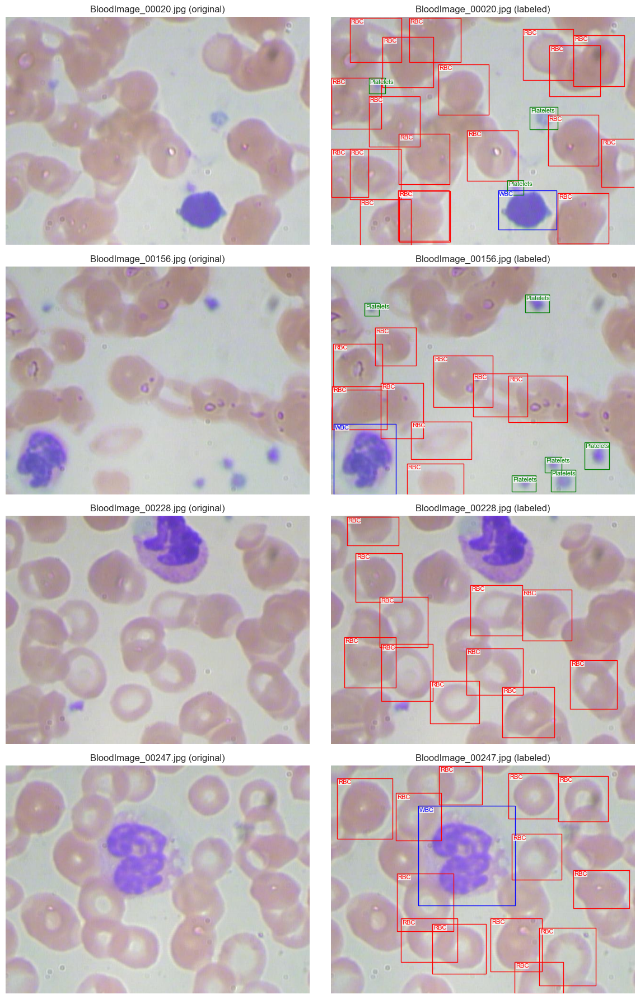

In [3]:
cell_types = ["RBC", "WBC", "Platelets"]

boxes_edges_colors = {
    cell_types[0]: "red",
    cell_types[1]: "blue",
    cell_types[2]: "green",
}

random.seed(seed)
sample_images = sorted(random.sample(os.listdir(images_path), 4))

_, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 18))

for i, image_name in enumerate(sample_images):
    image_path = images_path / image_name
    image = Image.open(image_path).convert("RGB")
    
    axes[i, 0].imshow(image)
    axes[i, 0].axis("off")
    axes[i, 0].set_title(f"{image_name} (original)")
    
    axes[i, 1].imshow(image)
    axes[i, 1].axis("off")
    axes[i, 1].set_title(f"{image_name} (labeled)")
    
    boxes = cells_df[cells_df.filename == image_name]
    for _, box in boxes.iterrows():
        cell_type = box.cell_type

        xmin, xmax = box.xmin, box.xmax
        ymin, ymax = box.ymin, box.ymax
        
        width = xmax - xmin
        height = ymax - ymin
        
        rect = patches.Rectangle(
            xy=(xmin, ymin), width=width, height=height,
            edgecolor=boxes_edges_colors[cell_type], facecolor="none",
        )
        axes[i, 1].add_patch(rect)

        axes[i, 1].text(
            x=xmin + 2, y=ymin + 12, s=cell_type,
            fontsize=8, color=boxes_edges_colors[cell_type],
            bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
        )

plt.tight_layout()

# Анализ данных

In [4]:
cells_counts_df = cells_df.pivot_table(
    index="filename",
    columns="cell_type",
    values="xmin",
    aggfunc="count",
    fill_value=0,
).reset_index()

cells_counts_df.columns.name = None
cells_counts_df = cells_counts_df.rename(columns={
    cell_types[0]: "rbc_count",
    cell_types[1]: "wbc_count",
    cell_types[2]: "platelets_count",
})
cells_counts_df = cells_counts_df[["filename", "rbc_count", "wbc_count", "platelets_count"]]

cells_counts_df["total_count"] = (
    cells_counts_df.wbc_count + cells_counts_df.rbc_count + cells_counts_df.platelets_count
)
cells_counts_df

,filename,rbc_count,wbc_count,platelets_count,total_count
0,BloodImage_00000.jpg,19,1,0,20
1,BloodImage_00001.jpg,18,1,0,19
2,BloodImage_00002.jpg,15,1,0,16
3,BloodImage_00003.jpg,15,1,1,17
4,BloodImage_00004.jpg,11,1,1,13
...,...,...,...,...,...
359,BloodImage_00405.jpg,14,1,0,15
360,BloodImage_00407.jpg,15,1,3,19
361,BloodImage_00408.jpg,15,1,2,18
362,BloodImage_00409.jpg,14,1,4,19


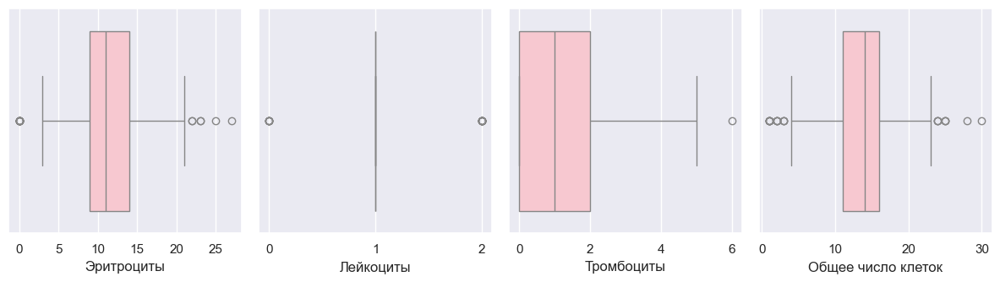

In [5]:
rbc_ru, wbc_ru, platelets_ru = "Эритроциты", "Лейкоциты", "Тромбоциты"

_, axes = plt.subplots(nrows=1, ncols=4, figsize=(12, 3.5))

columns = cells_counts_df.columns[1:]
xlabels = [rbc_ru, wbc_ru, platelets_ru, "Общее число клеток"]

for ax, column, xlabel in zip(axes, columns, xlabels):
    sns.boxplot(x=cells_counts_df[column], ax=ax, color="pink")
    ax.set_xlabel(xlabel)

    if xlabel == "Лейкоциты":
        ax.set_xticks([0, 1, 2])

plt.tight_layout()

In [6]:
cells_boxes_df = cells_df.copy()

cells_boxes_df["x_center"] = (cells_boxes_df.xmin + cells_boxes_df.xmax) / 2
cells_boxes_df["y_center"] = (cells_boxes_df.ymin + cells_boxes_df.ymax) / 2
cells_boxes_df["width"] = cells_boxes_df.xmax - cells_boxes_df.xmin
cells_boxes_df["height"] = cells_boxes_df.ymax - cells_boxes_df.ymin

(cells_boxes_df := cells_boxes_df.drop(columns=["xmin", "xmax", "ymin", "ymax"]))

,filename,cell_type,x_center,y_center,width,height
0,BloodImage_00000.jpg,WBC,375.5,276.5,231,199
1,BloodImage_00000.jpg,RBC,131.0,385.5,106,99
2,BloodImage_00000.jpg,RBC,116.0,286.5,106,99
3,BloodImage_00000.jpg,RBC,267.0,411.5,106,99
4,BloodImage_00000.jpg,RBC,460.0,398.5,92,93
...,...,...,...,...,...,...
4883,BloodImage_00410.jpg,Platelets,265.0,298.0,52,46
4884,BloodImage_00410.jpg,Platelets,155.0,290.0,68,60
4885,BloodImage_00410.jpg,Platelets,80.5,143.0,47,48
4886,BloodImage_00410.jpg,Platelets,15.0,306.5,28,41


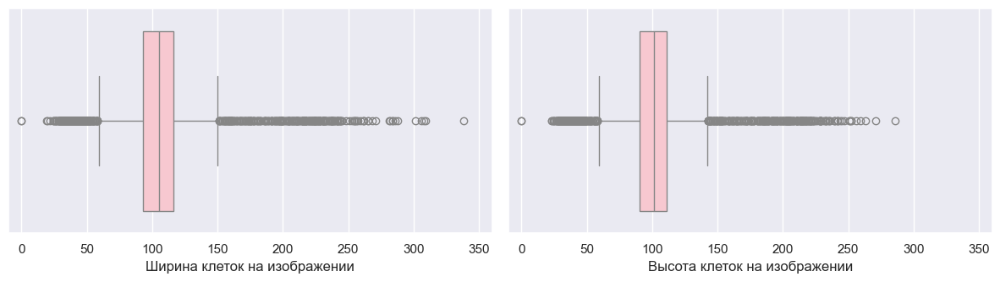

In [7]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 3.5))

columns = cells_boxes_df.columns[-2:]
xlabels = ["Ширина клеток на изображении", "Высота клеток на изображении"]

for ax, column, xlabel in zip(axes, columns, xlabels):
    sns.boxplot(x=cells_boxes_df[column], ax=ax, color="pink")
    ax.set_xlim(-10, 360)
    ax.set_xlabel(xlabel)

plt.tight_layout()

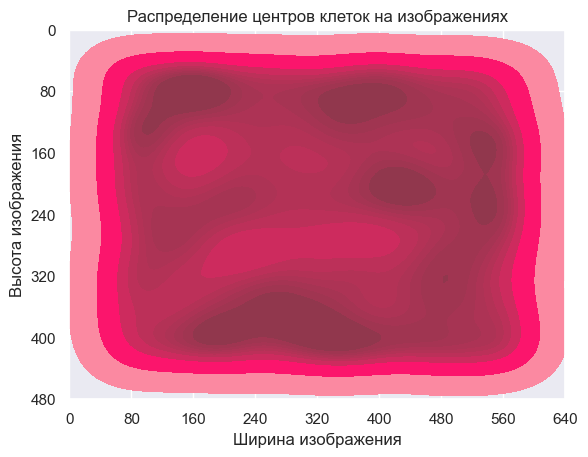

In [8]:
sns.kdeplot(data=cells_boxes_df, x="x_center", y="y_center", fill=True, color="Pink")
plt.xlim(0, image_width)
plt.ylim(0, image_height)
plt.xticks(range(0, image_width + 1, 80))
plt.yticks(range(0, image_height + 1, 80))
plt.gca().invert_yaxis()
plt.xlabel("Ширина изображения")
plt.ylabel("Высота изображения")
plt.title("Распределение центров клеток на изображениях");

# Подготовка данных для регрессии

In [9]:
def get_image_names_from_file(file_path):
    with open(file_path, encoding="utf-8") as file_in:
        return [line.strip() + ".jpg" for line in file_in.readlines()]


train_images = get_image_names_from_file(image_sets_path / "train.txt")
valid_images = get_image_names_from_file(image_sets_path / "val.txt")
test_images = get_image_names_from_file(image_sets_path / "test.txt")

print(
    f"Размер обучающей выборки: {len(train_images)}",
    f"Размер валидационной выборки: {len(valid_images)}",
    f"Размер тестовой выборки: {len(test_images)}",
    sep="\n"
)

Размер обучающей выборки: 205
Размер валидационной выборки: 87
Размер тестовой выборки: 72


In [10]:
class BloodCellDataset(Dataset):
    def __init__(self, images_path, cells_counts_df, transform=None):
        self.images_path = images_path
        self.cells_counts_df = cells_counts_df
        self.transform = transform
        self.image_names = list(self.cells_counts_df.index)

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, image_index):
        image_name = self.image_names[image_index]
        image_path = self.images_path / image_name
        image = Image.open(image_path).convert("RGB")
        image = self.transform(image)

        cells_counts = self.cells_counts_df.loc[image_name]
        target = torch.tensor(
            [cells_counts.rbc_count, cells_counts.wbc_count, cells_counts.platelets_count],
            dtype=torch.float32
        )

        return image, target


mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
image_size = (224, 224)

transform_aug = transforms.Compose([
    transforms.Resize(size=image_size),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
transform_base = transforms.Compose([
    transforms.Resize(size=image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

cells_counts_df_indexed = cells_counts_df.set_index("filename")

train_dataset = BloodCellDataset(
    images_path=images_path,
    cells_counts_df=cells_counts_df_indexed.loc[train_images],
    transform=transform_aug,
)
valid_dataset = BloodCellDataset(
    images_path=images_path,
    cells_counts_df=cells_counts_df_indexed.loc[valid_images],
    transform=transform_base,
)
test_dataset = BloodCellDataset(
    images_path=images_path,
    cells_counts_df=cells_counts_df_indexed.loc[test_images],
    transform=transform_base,
)

sample_image, sample_target = train_dataset[0]
print(f'Размерность изображений: {sample_image.shape}')
print(f'Пример целевого вектора: {sample_target}')

Размерность изображений: torch.Size([3, 224, 224])
Пример целевого вектора: tensor([18.,  1.,  0.])


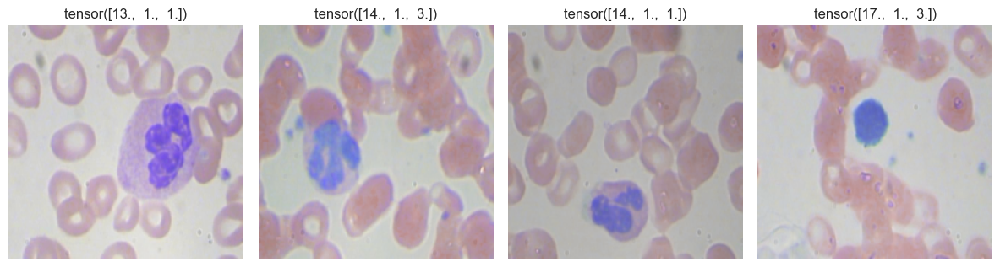

In [11]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


def get_image_array_from_tensor(image_tensor, mean, std):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    image_tensor = image_tensor * std_tensor + mean_tensor
    image_tensor = image_tensor.clamp(0, 1)
    image_array = image_tensor.permute(1, 2, 0).detach().cpu().numpy()

    return image_array


def show_batch(loader):
    images, targets = next(iter(loader))

    _, axes = plt.subplots(nrows=1, ncols=4, figsize=(12, 3.5))

    for i, ax in enumerate(axes):
        image_np = get_image_array_from_tensor(images[i], mean, std)
        ax.imshow(image_np)
        ax.axis("off")
        ax.set_title(targets[i])

    plt.tight_layout()


show_batch(train_loader)

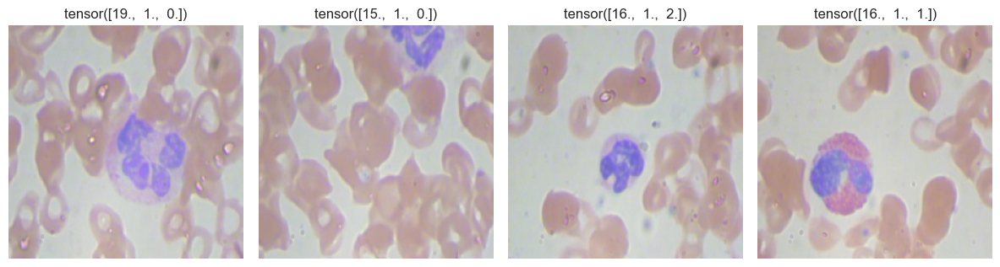

In [12]:
show_batch(valid_loader)

# Создание модели регрессии

In [13]:
class ResNet50Regressor(nn.Module):
    def __init__(self, out_features=3):
        super().__init__()
        self.backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

        self.backbone.fc = nn.Sequential(
            nn.Linear(self.backbone.fc.in_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, out_features)
        )
    
    def forward(self, x):
        return self.backbone(x)


class EarlyStopping:
    def __init__(self, patience, min_delta, mode):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_model_state = None
    
    def __call__(self, current_score, model):
        if self.best_score is None:
            self.best_score = current_score
            self.best_model_state = deepcopy(model.state_dict())

        elif (self.mode == "max" and current_score < self.best_score + self.min_delta) or \
             (self.mode == "min" and current_score > self.best_score - self.min_delta):
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        
        else:
            self.best_score = current_score
            self.best_model_state = deepcopy(model.state_dict())
            self.counter = 0


def train_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    return running_loss / total_samples


def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_targets = []
    all_preds = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

            all_targets.append(targets.cpu())
            all_preds.append(outputs.cpu())

    targets_t = torch.cat(all_targets, dim=0).numpy()
    preds_t = torch.cat(all_preds, dim=0).numpy()

    mae = np.mean(np.abs(targets_t - preds_t), axis=0)
    rmse = np.sqrt(np.mean((targets_t - preds_t)**2, axis=0))

    return running_loss / total_samples, mae, rmse, targets_t, preds_t


regression_model = ResNet50Regressor(out_features=3).to(current_device)
criterion = nn.MSELoss()

# Обучение модели регрессии

In [ ]:
learning_rate = 0.0001
n_epochs = 50

optimizer = optim.Adam(regression_model.parameters(), lr=learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

early_stopping = EarlyStopping(patience=7, min_delta=0.01, mode="min")

regression_history = {
    "train_loss": [],
    "valid_loss": [],
    "valid_mae": [],
    "valid_rmse": [],
}

print(f"Обучение модели {regression_model_name}:")
start_time = time()

for epoch in range(n_epochs):
    epoch_start_time = time()

    train_loss = train_epoch(
        regression_model, train_loader, optimizer, criterion, current_device
    )
    valid_loss, valid_mae, valid_rmse, _, _ = evaluate(
        regression_model, valid_loader, criterion, current_device
    )

    epoch_end_time = time()
    epoch_time = round(epoch_end_time - epoch_start_time)

    regression_history["train_loss"].append(train_loss)
    regression_history["valid_loss"].append(valid_loss)
    regression_history["valid_mae"].append(valid_mae)
    regression_history["valid_rmse"].append(valid_rmse)

    learning_rate_str = f"{optimizer.param_groups[0]["lr"]:.6f}".rstrip("0")
        
    print(f"Epoch {epoch + 1:2d}/{n_epochs} ({epoch_time}s)\n- "
          f"train_loss: {train_loss:.4f} - valid_loss: {valid_loss:.4f} - "
          f"valid_mae: [{valid_mae[0]:.2f} {valid_mae[1]:.2f} {valid_mae[2]:.2f}] - "
          f"valid_rmse: [{valid_rmse[0]:.2f} {valid_rmse[1]:.2f} {valid_rmse[2]:.2f}] - "
          f"lr: {learning_rate_str}")

    scheduler.step(valid_loss)

    early_stopping(valid_loss, regression_model)
    if early_stopping.early_stop:
        print(f"Ранняя остановка на эпохе {epoch + 1}")
        break

end_time = time()
elapsed_time = str(timedelta(seconds=round(end_time - start_time)))

regression_model.load_state_dict(early_stopping.best_model_state)
torch.save(regression_model.state_dict(), models_path / f"{regression_model_name}.pt")

best_epoch = len(regression_history["train_loss"]) - early_stopping.counter
regression_history["best_epoch"] = best_epoch
print(f"Лучшее значение функции потерь на валидации: {early_stopping.best_score:.4f} (эпоха {best_epoch})")
print(f"Время обучения модели '{regression_model_name}': {elapsed_time}")

regression_model.to("cpu")
torch.cuda.empty_cache()

Обучение модели ResNet50Regressor:
Epoch  1/50 (5s)
- train_loss: 44.6283 - valid_loss: 39.7678 - valid_mae: [9.85 0.76 0.94] - valid_rmse: [10.81 0.77 1.39] - lr: 0.0001
Epoch  2/50 (5s)
- train_loss: 31.1058 - valid_loss: 28.8529 - valid_mae: [8.28 0.47 0.92] - valid_rmse: [9.21 0.49 1.25] - lr: 0.0001
Epoch  3/50 (5s)
- train_loss: 19.8641 - valid_loss: 11.3949 - valid_mae: [4.74 0.16 1.00] - valid_rmse: [5.72 0.23 1.19] - lr: 0.0001
Epoch  4/50 (5s)
- train_loss: 10.6016 - valid_loss: 7.8722 - valid_mae: [3.78 0.21 1.09] - valid_rmse: [4.69 0.28 1.25] - lr: 0.0001
Epoch  5/50 (5s)
- train_loss: 5.2107 - valid_loss: 4.8398 - valid_mae: [2.58 0.23 1.10] - valid_rmse: [3.58 0.29 1.27] - lr: 0.0001
Epoch  6/50 (5s)
- train_loss: 3.1611 - valid_loss: 5.7367 - valid_mae: [2.79 0.14 0.90] - valid_rmse: [3.98 0.21 1.15] - lr: 0.0001
Epoch  7/50 (5s)
- train_loss: 2.6290 - valid_loss: 5.9430 - valid_mae: [2.86 0.15 0.87] - valid_rmse: [4.05 0.21 1.17] - lr: 0.0001
Epoch  8/50 (5s)
- train_l

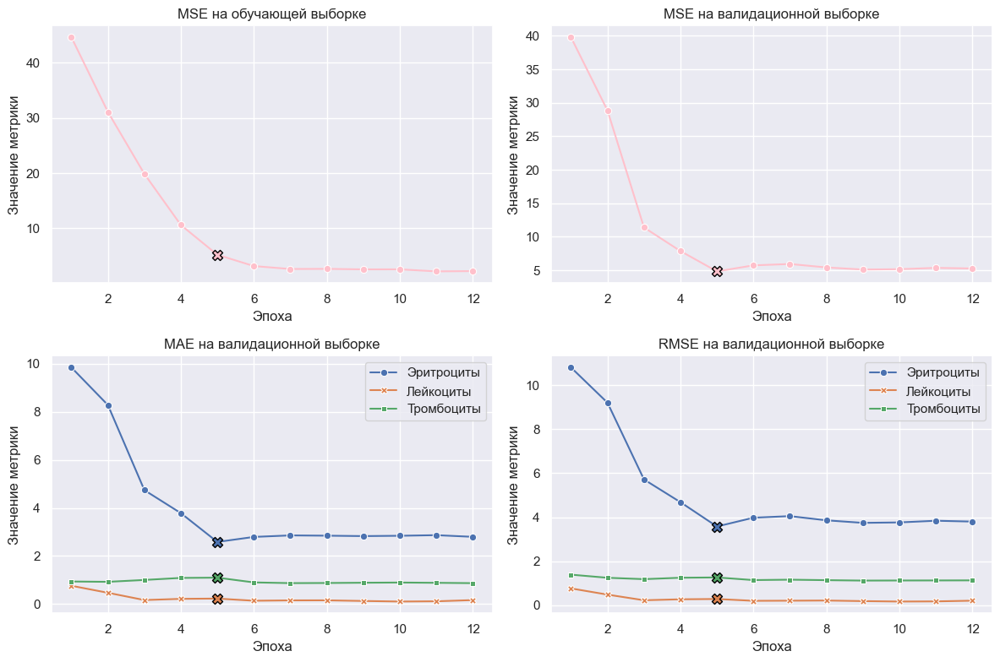

In [ ]:
records_list = []

for epoch, (train_loss, valid_loss, valid_mae, valid_rmse) in enumerate(zip(
    regression_history["train_loss"], regression_history["valid_loss"],
    regression_history["valid_mae"], regression_history["valid_rmse"],
)):
    records_list.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "valid_loss": valid_loss,
        "valid_mae_rbc": valid_mae[0],
        "valid_mae_wbc": valid_mae[1],
        "valid_mae_platelets": valid_mae[2],
        "valid_rmse_rbc": valid_rmse[0],
        "valid_rmse_wbc": valid_rmse[1],
        "valid_rmse_platelets": valid_rmse[2],
    })

records_df = pd.DataFrame(records_list)

records_mae_df = records_df.melt(
    id_vars="epoch",
    value_vars=["valid_mae_rbc", "valid_mae_wbc", "valid_mae_platelets"],
    var_name="cell_type",
    value_name="valid_mae",
)
records_mae_df.cell_type = records_mae_df.cell_type.map({
    "valid_mae_rbc": rbc_ru,
    "valid_mae_wbc": wbc_ru,
    "valid_mae_platelets": platelets_ru,
})

records_rmse_df = records_df.melt(
    id_vars="epoch",
    value_vars=["valid_rmse_rbc", "valid_rmse_wbc", "valid_rmse_platelets"],
    var_name="cell_type",
    value_name="valid_rmse",
)
records_rmse_df.cell_type = records_rmse_df.cell_type.map({
    "valid_rmse_rbc": rbc_ru,
    "valid_rmse_wbc": wbc_ru,
    "valid_rmse_platelets": platelets_ru,
})

best_epoch = regression_history["best_epoch"]

plot_params = {
    "y": ["train_loss", "valid_loss", "valid_mae", "valid_rmse"],
    "title": [
        "MSE на обучающей выборке",
        "MSE на валидационной выборке",
        "MAE на валидационной выборке",
        "RMSE на валидационной выборке",
    ],
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
axes = axes.flatten()

for i, ax in enumerate(axes[:2]):
    metric = plot_params["y"][i]

    sns.lineplot(
        data=records_df, x="epoch", y=metric, color="pink",
        markers=True, marker="o", ax=ax,
    ).set(
        title=plot_params["title"][i], xlabel="Эпоха", ylabel="Значение метрики",
        xticks=range(0, len(records_df) + 1, 2),
    )

    ax.scatter(
        x=best_epoch, y=regression_history[metric][best_epoch - 1],
        s=75, color="pink", marker="X", edgecolor="black", zorder=5,
    )

for i, ax in enumerate(axes[2:], start=2):
    records = records_mae_df if i == 2 else records_rmse_df
    metric = plot_params["y"][i]

    sns.lineplot(
        data=records, x="epoch", y=metric, hue="cell_type",
        style="cell_type", dashes=False, markers=True, ax=ax,
    ).set(
        title=plot_params["title"][i], xlabel="Эпоха", ylabel="Значение метрики",
        xticks=range(0, len(records_df) + 1, 2),
    )

    for j in range(3):
        ax.scatter(
            x=best_epoch, y=regression_history[metric][best_epoch - 1][j],
            s=75, marker="X", edgecolor="black", zorder=5,
        )

    ax.legend(title="", loc="upper right")

plt.tight_layout()

In [ ]:
regression_model = regression_model.to(current_device)

test_loss, test_mae, test_rmse, y_true, y_pred = evaluate(
    regression_model, test_loader, criterion, current_device
)

print(
    f"MSE на обучающей выборке: {regression_history["train_loss"][best_epoch - 1]:.4f}",
    f"MSE на валидационной выборке: {regression_history["valid_loss"][best_epoch - 1]:.4f}",
    f"MSE на тестовой выборке: {test_loss:.4f}",
    sep="\n"
)

results_df = pd.DataFrame(data={
    "valid_mae": regression_history["valid_mae"][best_epoch - 1],
    "test_mae": test_mae,
    "valid_rmse": regression_history["valid_rmse"][best_epoch - 1],
    "test_rmse": test_rmse,
}, index=[rbc_ru, wbc_ru, platelets_ru])

results_df.style.format("{:.4f}")

MSE на обучающей выборке: 5.2107
MSE на валидационной выборке: 4.8398
MSE на тестовой выборке: 5.1617


,valid_mae,test_mae,valid_rmse,test_rmse
Эритроциты,2.5827,2.6815,3.5816,3.7321
Лейкоциты,0.2258,0.2786,0.2892,0.4013
Тромбоциты,1.0962,1.0428,1.2681,1.1813


# Тестирование модели регрессии

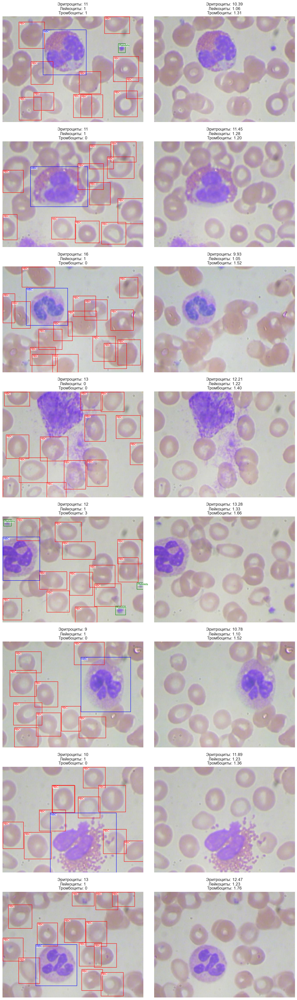

In [ ]:
random.seed(seed)
sample_indices = random.sample(range(len(test_dataset)), 8)

_, axes = plt.subplots(nrows=8, ncols=2, figsize=(12, 40))

for i, image_index in enumerate(sample_indices):
    image_name = test_dataset.image_names[image_index]
    image_path = test_dataset.images_path / image_name
    image = Image.open(image_path).convert("RGB")

    true_counts = y_true[image_index]
    pred_counts = y_pred[image_index]

    axes[i, 0].imshow(image)
    axes[i, 0].axis("off")
    axes[i, 0].set_title(
        f"{rbc_ru}: {true_counts[0]:.0f}\n"
        f"{wbc_ru}: {true_counts[1]:.0f}\n"
        f"{platelets_ru}: {true_counts[2]:.0f}"
    )

    boxes = cells_df[cells_df.filename == image_name]
    for _, box in boxes.iterrows():
        cell_type = box.cell_type

        xmin, xmax = box.xmin, box.xmax
        ymin, ymax = box.ymin, box.ymax
        
        width = xmax - xmin
        height = ymax - ymin

        rect = patches.Rectangle(
            xy=(xmin, ymin), width=width, height=height,
            edgecolor=boxes_edges_colors[cell_type], facecolor="none",
        )
        axes[i, 0].add_patch(rect)

        axes[i, 0].text(
            x=xmin + 2, y=ymin + 12, s=cell_type,
            fontsize=8, color=boxes_edges_colors[cell_type],
            bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
        )

    axes[i, 1].imshow(image)
    axes[i, 1].axis("off")
    axes[i, 1].set_title(
        f"{rbc_ru}: {pred_counts[0]:.2f}\n"
        f"{wbc_ru}: {pred_counts[1]:.2f}\n"
        f"{platelets_ru}: {pred_counts[2]:.2f}"
    )

plt.tight_layout()

# Подготовка данных для детекции

In [14]:
def prepare_yolo_dataset(images_path, images_by_folder, out_path, labels_df):
    for folder, images in images_by_folder.items():
        out_images_path = out_path / "images" / folder
        out_labels_path = out_path / "labels" / folder

        out_images_path.mkdir(parents=True, exist_ok=True)
        out_labels_path.mkdir(parents=True, exist_ok=True)

        for image_name in images:
            shutil.copy(images_path / image_name, out_images_path / image_name)
            
            label_name = image_name.replace(".jpg", ".txt")
            with open(out_labels_path / label_name, "w") as file_out:
                for _, row in labels_df[labels_df.filename == image_name].iterrows():
                    file_out.write(
                        f"{int(row.cell_type)} "
                        f"{row.x_center:.6f} {row.y_center:.6f} "
                        f"{row.width:.6f} {row.height:.6f}\n"
                    )


images_by_folder = {
    "train": train_images,
    "valid": valid_images,
    "test": test_images,
}

cells_boxes_norm_df = cells_boxes_df.copy()

cells_boxes_norm_df.x_center = cells_boxes_norm_df.x_center / image_width
cells_boxes_norm_df.y_center = cells_boxes_norm_df.y_center / image_height
cells_boxes_norm_df.width = cells_boxes_norm_df.width / image_width
cells_boxes_norm_df.height = cells_boxes_norm_df.height / image_height

cells_boxes_norm_df.cell_type = cells_boxes_norm_df.cell_type.map({
    cell_types[0]: 0, cell_types[1]: 1, cell_types[2]: 2
})

if not os.listdir(yolo_data_path):
    prepare_yolo_dataset(
        images_by_folder=images_by_folder,
        out_path=yolo_data_path,
        images_path=images_path,
        labels_df=cells_boxes_norm_df,
    )

# Создание и обучение модели детекции

In [ ]:
detection_model = YOLO(model="yolo26n.pt")

plt.style.use("default")

detection_train_results = detection_model.train(
    data=yolo_conf_path,
    epochs=100,
    batch=batch_size,
    imgsz=image_width,
    device=current_device.type,
    workers=4,
    patience=10,
)

shutil.copy(
    detection_train_results.save_dir / "weights" / "best.pt",
    models_path / f"{detection_model_name}.pt"
)

with open(yolo_train_results_path, "wb") as file_out:
    pickle.dump(detection_train_results, file_out)

Ultralytics 8.4.53  Python-3.12.10 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\YOLO\bccd.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10,

In [ ]:
detection_model = YOLO(models_path / f"{detection_model_name}.pt", task="detect")

detection_test_results = detection_model.val(
    data=yolo_conf_path,
    split="test",
    name="test",
)

with open(yolo_test_results_path, "wb") as file_out:
    pickle.dump(detection_test_results, file_out)

Ultralytics 8.4.52  Python-3.12.10 torch-2.7.0+cpu CPU (13th Gen Intel Core i5-13420H)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 245.467.2 MB/s, size: 20.4 KB)
val: Scanning D:\VSCodeProjects\MachineLearning\Курс 3 - Нейронные сети и глубокое обучение\3.8 Автоматизация микроскопии\data\YOLO\labels\test.cache... 72 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 72/72  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.3it/s 3.8s1.1ss
                   all         72        945      0.832      0.808      0.872      0.588
                   RBC         69        805      0.753      0.764      0.834      0.568
                   WBC         68         71      0.825      0.993       0.93      0.752
             Platelets         39         69       0.92      0.666      0.851      0.444
Speed: 1.0ms preprocess, 43.8ms inference, 0.

# Тестирование модели детекции

In [15]:
detection_model = YOLO(models_path / f"{detection_model_name}.pt", task="detect")

with open(yolo_train_results_path, "rb") as file_in:
    detection_train_results = pickle.load(file_in)

with open(yolo_test_results_path, "rb") as file_in:
    detection_test_results = pickle.load(file_in)

sns.set_theme()

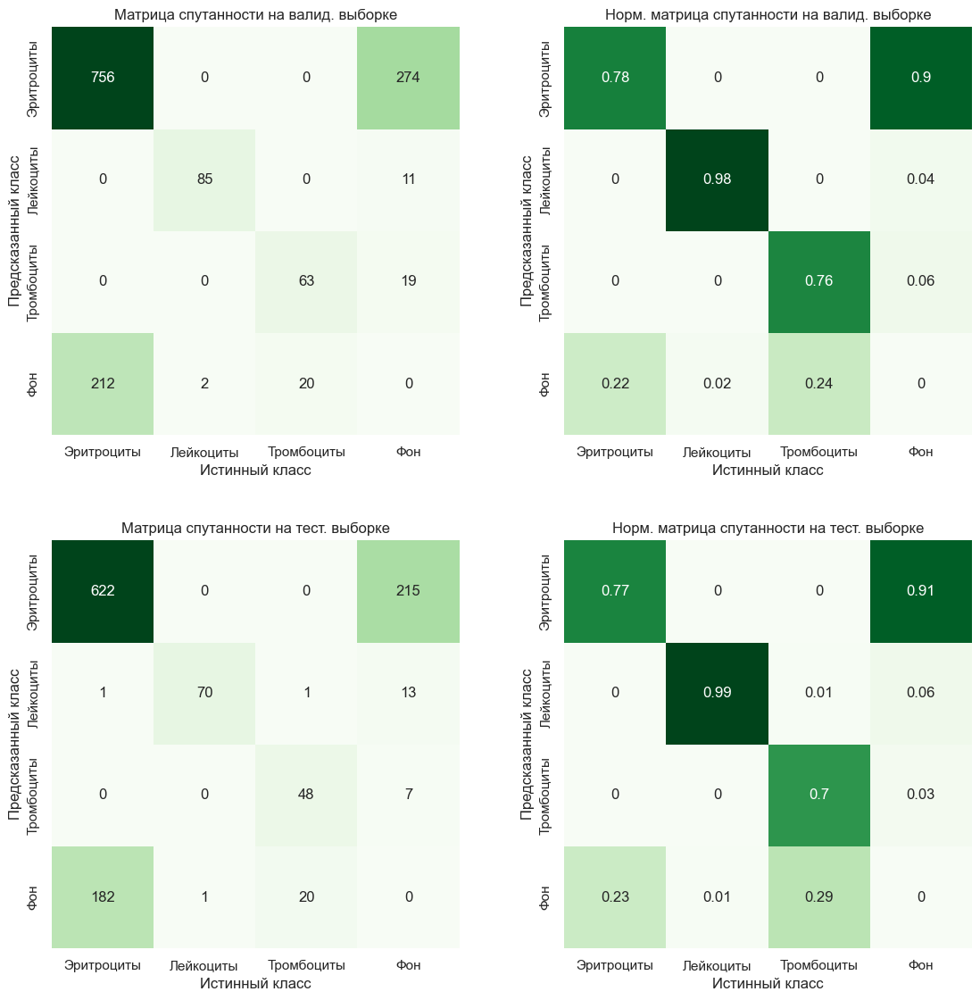

In [16]:
valid_cm = detection_train_results.confusion_matrix.matrix
valid_cm_norm = (valid_cm / (valid_cm.sum(axis=0, keepdims=True) + 1e-5)).round(2)
test_cm = detection_test_results.confusion_matrix.matrix
test_cm_norm = (test_cm / (test_cm.sum(axis=0, keepdims=True) + 1e-5)).round(2)

cm_list = [valid_cm, valid_cm_norm, test_cm, test_cm_norm]
cm_titles = [
    "Матрица спутанности на валид. выборке",
    "Норм. матрица спутанности на валид. выборке",
    "Матрица спутанности на тест. выборке",
    "Норм. матрица спутанности на тест. выборке",
]
cm_labels = [rbc_ru, wbc_ru, platelets_ru, "Фон"]

_, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
axes = axes.flatten()

for i, ax in enumerate(axes):
    sns.heatmap(
        data=cm_list[i], cmap="Greens", annot=True, fmt=".3g", cbar=False, square=True,
        xticklabels=cm_labels, yticklabels=cm_labels, ax=ax,
    ).set(
        title=cm_titles[i], xlabel="Истинный класс", ylabel="Предсказанный класс",
    )

plt.tight_layout(pad=3)

In [17]:
print(f"Размер валидационной выборки: {len(valid_images)}")
pd.DataFrame(detection_train_results.summary()).style.hide(axis="index")

Размер валидационной выборки: 87


Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95
RBC,83,968,0.724950,0.783060,0.752880,0.830850,0.578690
WBC,86,87,0.886480,0.987350,0.934200,0.982910,0.802110
Platelets,45,83,0.767440,0.771080,0.769260,0.813210,0.425660


In [18]:
print(f"Размер тестовой выборки: {len(test_images)}")
pd.DataFrame(detection_test_results.summary()).style.hide(axis="index")

Размер тестовой выборки: 72


Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95
RBC,69,805,0.752770,0.764020,0.758350,0.834300,0.568450
WBC,68,71,0.824590,0.993170,0.901060,0.929630,0.752430
Platelets,39,69,0.919970,0.666440,0.772940,0.850850,0.443730


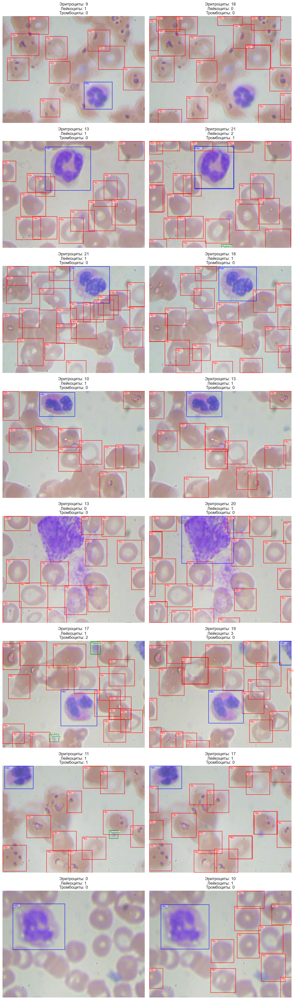

In [19]:
def get_counts_from_yolo_results(results):
    if results[0].boxes is None:
        return [0, 0, 0]
    cls = results[0].boxes.cls.cpu().numpy().astype(int)
    counts = np.bincount(cls, minlength=3)[:3]
    return counts


random.seed(seed)
sample_images = random.sample(random.sample(test_images, 36), 8)

_, axes = plt.subplots(nrows=8, ncols=2, figsize=(12, 40))

for i, image_name in enumerate(sample_images):
    image_path = images_path / image_name
    image = Image.open(image_path).convert("RGB")
    
    true_row = cells_counts_df[cells_counts_df.filename == image_name]
    if not true_row.empty:
        true_counts = [
            true_row.rbc_count.values[0],
            true_row.wbc_count.values[0],
            true_row.platelets_count.values[0],
        ]
    else:
        true_counts = [0, 0, 0]

    axes[i, 0].imshow(image)
    axes[i, 0].axis("off")
    axes[i, 0].set_title(
        f"{rbc_ru}: {true_counts[0]}\n"
        f"{wbc_ru}: {true_counts[1]}\n"
        f"{platelets_ru}: {true_counts[2]}"
    )

    true_boxes = cells_df[cells_df.filename == image_name]
    for _, box in true_boxes.iterrows():
        cell_type = box.cell_type

        xmin, xmax = box.xmin, box.xmax
        ymin, ymax = box.ymin, box.ymax
        
        width = xmax - xmin
        height = ymax - ymin

        rect = patches.Rectangle(
            xy=(xmin, ymin), width=width, height=height,
            edgecolor=boxes_edges_colors[cell_type], facecolor="none",
        )
        axes[i, 0].add_patch(rect)

        axes[i, 0].text(
            x=xmin + 2, y=ymin + 12, s=cell_type,
            fontsize=8, color=boxes_edges_colors[cell_type],
            bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
        )
    
    results = detection_model(image_path, verbose=False)
    pred_counts = get_counts_from_yolo_results(results)
    
    axes[i, 1].imshow(image)
    axes[i, 1].axis("off")
    axes[i, 1].set_title(
        f"{rbc_ru}: {pred_counts[0]}\n"
        f"{wbc_ru}: {pred_counts[1]}\n"
        f"{platelets_ru}: {pred_counts[2]}"
    )
    
    if results[0].boxes is not None:
        pred_boxes = results[0].boxes

        for box in pred_boxes:
            cell_type = cell_types[int(box.cls[0].cpu().numpy())]
            
            xmin, ymin, xmax, ymax = box.xyxy[0].cpu().numpy()
            width = xmax - xmin
            height = ymax - ymin

            rect = patches.Rectangle(
                xy=(xmin, ymin), width=width, height=height,
                edgecolor=boxes_edges_colors[cell_type], facecolor="none",
            )
            axes[i, 1].add_patch(rect)

            axes[i, 1].text(
                x=xmin + 2, y=ymin + 12, s=cell_type,
                fontsize=8, color=boxes_edges_colors[cell_type],
                bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
            )

plt.tight_layout()

# Сравнение предсказаний двух моделей

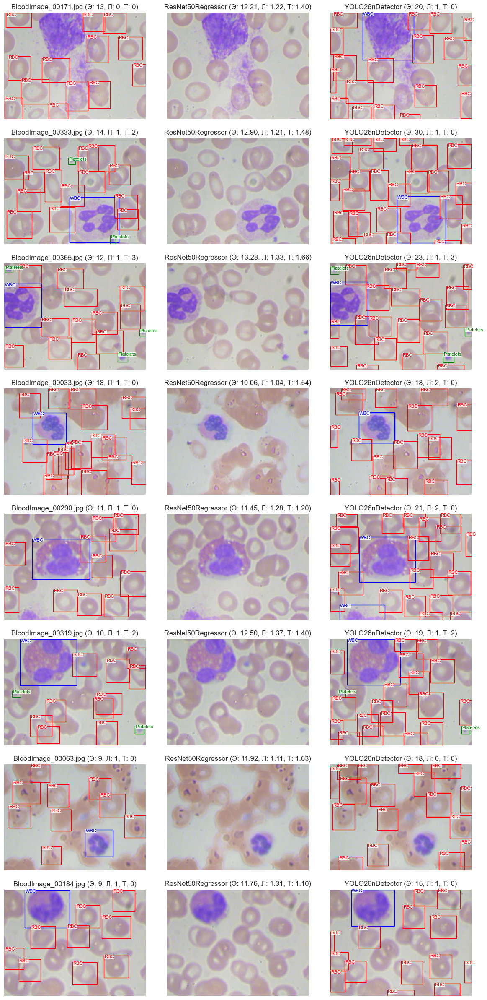

In [20]:
regression_model.load_state_dict(
    torch.load(
        models_path / f"{regression_model_name}.pt",
        map_location=current_device
    )
)

_, _, _, y_true, y_pred = evaluate(
    regression_model, test_loader, criterion, current_device
)

rbc_ru_short = rbc_ru[0]
wbc_ru_short = wbc_ru[0]
platelets_ru_short = platelets_ru[0]

random.seed(seed)
sample_indices = random.sample(random.sample(range(len(test_images)), 18), 8)

_, axes = plt.subplots(nrows=8, ncols=3, figsize=(12, 24))

for i, image_index in enumerate(sample_indices):
    image_name = test_images[image_index]
    image_path = images_path / image_name
    image = Image.open(image_path).convert("RGB")
    
    axes[i, 0].imshow(image)
    axes[i, 0].axis("off")
    
    true_counts = y_true[image_index]
    axes[i, 0].set_title(
        f"{image_name} ({rbc_ru_short}: {true_counts[0]:.0f}, "
        f"{wbc_ru_short}: {true_counts[1]:.0f}, "
        f"{platelets_ru_short}: {true_counts[2]:.0f})"
    )
    
    true_boxes = cells_df[cells_df.filename == image_name]
    for _, box in true_boxes.iterrows():
        cell_type = box.cell_type

        xmin, xmax = box.xmin, box.xmax
        ymin, ymax = box.ymin, box.ymax

        width = xmax - xmin
        height = ymax - ymin
        
        rect = patches.Rectangle(
            xy=(xmin, ymin), width=width, height=height,
            edgecolor=boxes_edges_colors[cell_type], facecolor="none",
        )
        axes[i, 0].add_patch(rect)

        axes[i, 0].text(
            x=xmin + 2, y=ymin + 12, s=cell_type,
            fontsize=8, color=boxes_edges_colors[cell_type],
            bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
        )
    
    axes[i, 1].imshow(image)
    axes[i, 1].axis("off")
    
    pred_counts_reg = y_pred[image_index]
    axes[i, 1].set_title(
        f"{regression_model_name} ({rbc_ru_short}: {pred_counts_reg[0]:.2f}, "
        f"{wbc_ru_short}: {pred_counts_reg[1]:.2f}, "
        f"{platelets_ru_short}: {pred_counts_reg[2]:.2f})"
    )

    axes[i, 2].imshow(image)
    axes[i, 2].axis("off")
    
    results = detection_model(image_path, verbose=False)
    pred_counts_yolo = get_counts_from_yolo_results(results)
    
    axes[i, 2].set_title(
        f"{detection_model_name} ({rbc_ru_short}: {pred_counts_yolo[0]}, "
        f"{wbc_ru_short}: {pred_counts_yolo[1]}, "
        f"{platelets_ru_short}: {pred_counts_yolo[2]})"
    )
    
    if results[0].boxes is not None:
        pred_boxes = results[0].boxes
        
        for box in pred_boxes:
            cell_type = cell_types[int(box.cls[0].cpu().numpy())]
            
            xmin, ymin, xmax, ymax = box.xyxy[0].cpu().numpy()
            width = xmax - xmin
            height = ymax - ymin

            rect = patches.Rectangle(
                xy=(xmin, ymin), width=width, height=height,
                edgecolor=boxes_edges_colors[cell_type], facecolor="none",
            )
            axes[i, 2].add_patch(rect)

            axes[i, 2].text(
                x=xmin + 2, y=ymin + 12, s=cell_type,
                fontsize=8, color=boxes_edges_colors[cell_type],
                bbox=dict(facecolor="white", alpha=0.75, pad=0, edgecolor="none"),
            )

plt.tight_layout(h_pad=1.5, w_pad=0.5)

# Реализация OOD-детекции

In [21]:
def enable_dropout(m):
    if isinstance(m, nn.Dropout):
        m.train()


def mc_dropout_predict(model, image_tensor, n_iter=30):
    model.eval()
    model.apply(enable_dropout)

    preds = []
    with torch.no_grad():
        for _ in range(n_iter):
            pred = model(image_tensor.to(current_device)).cpu().numpy()
            preds.append(pred)
    preds = np.array(preds).squeeze()

    return preds.var(axis=0)


def image_to_tensor(image, transform):
    return transform(image).unsqueeze(0)


def add_gaussian_blur(image, radius=7):
    return image.filter(ImageFilter.GaussianBlur(radius=radius))


def add_gaussian_noise(image, noise_level=1):
    image_tensor = transforms.ToTensor()(image)
    random_noise = torch.randn_like(image_tensor) * noise_level
    noisy_tensor = image_tensor + random_noise
    noisy_tensor = torch.clamp(noisy_tensor, 0., 1.)
    return transforms.ToPILImage()(noisy_tensor)


blood_vars = []
blur_vars = []
noisy_vars = []

for image_name in test_images:
    image = Image.open(images_path / image_name).convert("RGB")
    var = mc_dropout_predict(
        model=regression_model,
        image_tensor=image_to_tensor(image, transform_base),
    )
    blood_vars.append(var.sum())

    blur_image = add_gaussian_blur(image)
    var = mc_dropout_predict(
        model=regression_model,
        image_tensor=image_to_tensor(blur_image, transform_base),
    )
    blur_vars.append(var.sum())
    
    noisy_image = add_gaussian_noise(image)
    var = mc_dropout_predict(
        model=regression_model,
        image_tensor=image_to_tensor(noisy_image, transform_base),
    )
    noisy_vars.append(var.sum())

bacteria_paths = list(bacteria_path.glob("*.jpg"))
bacteria_vars = []
for image_path in bacteria_paths:
    bacteria_image = Image.open(image_path).convert("RGB")
    var = mc_dropout_predict(
        model=regression_model,
        image_tensor=image_to_tensor(bacteria_image, transform_base),
    )
    bacteria_vars.append(var.sum())

for bacteria_path, bacteria_var in zip(bacteria_paths, bacteria_vars):
    print(f"{bacteria_path.stem}.jpg - {bacteria_var:.3f}")

BacteriaImage_01.jpg - 2.473
BacteriaImage_02.jpg - 5.617
BacteriaImage_03.jpg - 6.289
BacteriaImage_04.jpg - 4.347
BacteriaImage_05.jpg - 8.440
BacteriaImage_06.jpg - 9.048
BacteriaImage_07.jpg - 3.652
BacteriaImage_08.jpg - 3.960
BacteriaImage_09.jpg - 5.570
BacteriaImage_10.jpg - 7.527
BacteriaImage_11.jpg - 3.330
BacteriaImage_12.jpg - 2.214
BacteriaImage_13.jpg - 3.476
BacteriaImage_14.jpg - 3.086
BacteriaImage_15.jpg - 3.966
BacteriaImage_16.jpg - 3.425


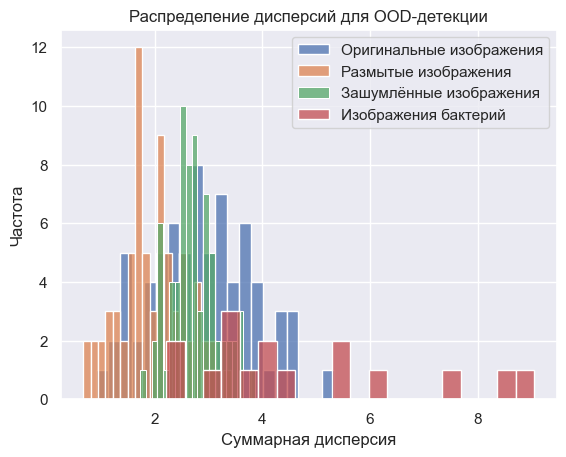

In [22]:
sns.histplot(data=blood_vars, bins=20, alpha=0.75, label="Оригинальные изображения")
sns.histplot(data=blur_vars, bins=20, alpha=0.75, label="Размытые изображения")
sns.histplot(data=noisy_vars, bins=20, alpha=0.75, label="Зашумлённые изображения")
sns.histplot(data=bacteria_vars, bins=20, alpha=0.75, label="Изображения бактерий")

plt.title("Распределение дисперсий для OOD-детекции")
plt.xlabel("Суммарная дисперсия")
plt.ylabel("Частота")
plt.legend();

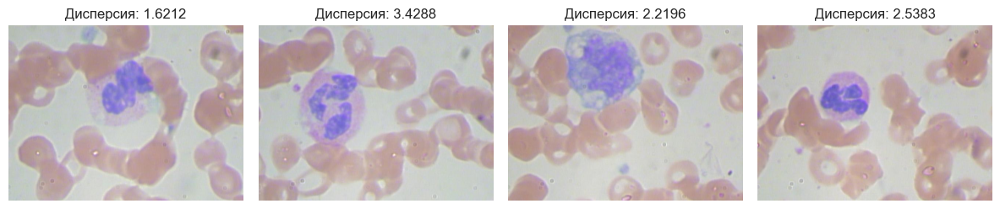

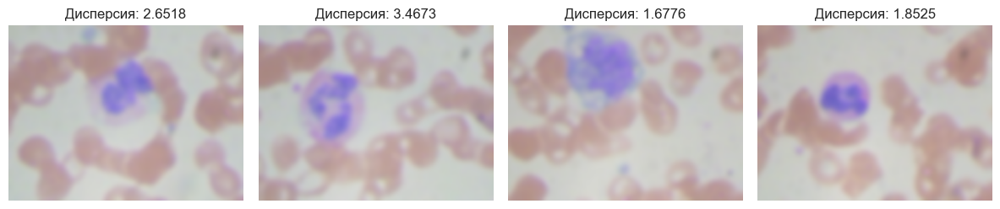

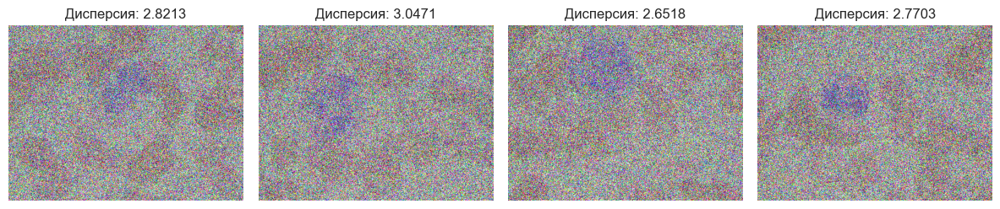

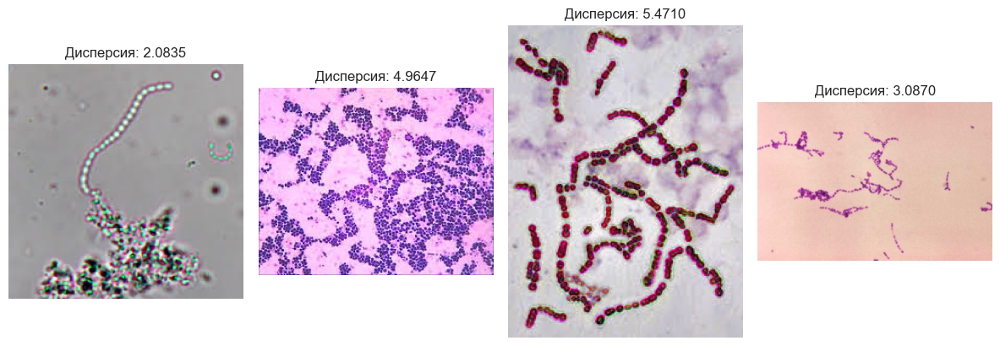

In [26]:
def show_ood_samples(images, vars):
    _, axes = plt.subplots(nrows=1, ncols=len(images), figsize=(12, 12))

    for i, (image, var) in enumerate(zip(images, vars)):
        axes[i].imshow(image)
        axes[i].axis("off")
        axes[i].set_title(f"Дисперсия: {var:.4f}")

    plt.tight_layout()


blood_samples = []
blur_samples = []
noisy_samples = []
bacteria_samples = []
for image_name, bacteria_path in zip(test_images[:4], bacteria_paths[:4]):
    image = Image.open(images_path / image_name).convert("RGB")
    blood_samples.append(image)
    blur_samples.append(add_gaussian_blur(image))
    noisy_samples.append(add_gaussian_noise(image))
    bacteria_samples.append(Image.open(bacteria_path).convert("RGB"))

blood_samples_vars = [mc_dropout_predict(
    model=regression_model, image_tensor=image_to_tensor(image, transform_base)
).sum() for image in blood_samples]
blur_samples_vars = [mc_dropout_predict(
    model=regression_model, image_tensor=image_to_tensor(image, transform_base)
).sum() for image in blur_samples]
noisy_samples_vars = [mc_dropout_predict(
    model=regression_model, image_tensor=image_to_tensor(image, transform_base)
).sum() for image in noisy_samples]
bacteria_samples_vars = [mc_dropout_predict(
    model=regression_model, image_tensor=image_to_tensor(image, transform_base)
).sum() for image in bacteria_samples]

show_ood_samples(blood_samples, blood_samples_vars)
show_ood_samples(blur_samples, blur_samples_vars)
show_ood_samples(noisy_samples, noisy_samples_vars)
show_ood_samples(bacteria_samples, bacteria_samples_vars)